# Homework 4

## Data Preparation

In [1]:
import os
import pandas as pd
import numpy as np

In [2]:
folders = [
    "bending1",
    "bending2",
    "cycling",
    "lying",
    "sitting",
    "standing",
    "walking"
]

for folder in folders:
    print(folder, os.listdir(folder))

bending1 ['dataset1.csv', 'dataset2.csv', 'dataset3.csv', 'dataset4.csv', 'dataset5.csv', 'dataset6.csv', 'dataset7.csv']
bending2 ['dataset1.csv', 'dataset2.csv', 'dataset3.csv', 'dataset4.csv', 'dataset5.csv', 'dataset6.csv']
cycling ['dataset1.csv', 'dataset10.csv', 'dataset11.csv', 'dataset12.csv', 'dataset13.csv', 'dataset14.csv', 'dataset15.csv', 'dataset2.csv', 'dataset3.csv', 'dataset4.csv', 'dataset5.csv', 'dataset6.csv', 'dataset7.csv', 'dataset8.csv', 'dataset9.csv']
lying ['dataset1.csv', 'dataset10.csv', 'dataset11.csv', 'dataset12.csv', 'dataset13.csv', 'dataset14.csv', 'dataset15.csv', 'dataset2.csv', 'dataset3.csv', 'dataset4.csv', 'dataset5.csv', 'dataset6.csv', 'dataset7.csv', 'dataset8.csv', 'dataset9.csv']
sitting ['dataset1.csv', 'dataset10.csv', 'dataset11.csv', 'dataset12.csv', 'dataset13.csv', 'dataset14.csv', 'dataset15.csv', 'dataset2.csv', 'dataset3.csv', 'dataset4.csv', 'dataset5.csv', 'dataset6.csv', 'dataset7.csv', 'dataset8.csv', 'dataset9.csv']
standing 

In [3]:
column_names = [
    "time",
    "avg_rss12",
    "var_rss12",
    "avg_rss13",
    "var_rss13",
    "avg_rss23",
    "var_rss23"
]

In [4]:
test_files = {}

for folder in folders:
    if folder in ["bending1", "bending2"]:
        test_files[folder] = ["dataset1.csv", "dataset2.csv"]
    else:
        test_files[folder] = ["dataset1.csv", "dataset2.csv", "dataset3.csv"]

test_files

{'bending1': ['dataset1.csv', 'dataset2.csv'],
 'bending2': ['dataset1.csv', 'dataset2.csv'],
 'cycling': ['dataset1.csv', 'dataset2.csv', 'dataset3.csv'],
 'lying': ['dataset1.csv', 'dataset2.csv', 'dataset3.csv'],
 'sitting': ['dataset1.csv', 'dataset2.csv', 'dataset3.csv'],
 'standing': ['dataset1.csv', 'dataset2.csv', 'dataset3.csv'],
 'walking': ['dataset1.csv', 'dataset2.csv', 'dataset3.csv']}

In [5]:
train_data = []
test_data = []

for folder in folders:
    for file in os.listdir(folder):
        if file.endswith(".csv"):
            file_info = (folder, file)

            if file in test_files[folder]:
                test_data.append(file_info)
            else:
                train_data.append(file_info)

print("Number of training instances:", len(train_data))
print("Number of test instances:", len(test_data))
print("Total instances:", len(train_data) + len(test_data))

Number of training instances: 69
Number of test instances: 19
Total instances: 88


## Feature Extraction

In [6]:
time_series_columns = [
    "avg_rss12",
    "var_rss12",
    "avg_rss13",
    "var_rss13",
    "avg_rss23",
    "var_rss23"
]

def extract_features(data):
    features = {}

    for i, column in enumerate(time_series_columns, start=1):
        series = data[column]

        features[f"min{i}"] = series.min()
        features[f"max{i}"] = series.max()
        features[f"mean{i}"] = series.mean()
        features[f"median{i}"] = series.median()
        features[f"std{i}"] = series.std()
        features[f"1st_quart{i}"] = series.quantile(0.25)
        features[f"3rd_quart{i}"] = series.quantile(0.75)

    return features

In [7]:
from io import StringIO

all_features = []

for folder, file in train_data:
    file_path = os.path.join(folder, file)

    with open(file_path, "r") as f:
        lines = f.readlines()

    cleaned_lines = [
        line.rstrip().rstrip(",")
        for line in lines[5:]
    ]

    data = pd.read_csv(
        StringIO("\n".join(cleaned_lines)),
        header=None,
        names=column_names,
        sep=r",|\s+",
        engine="python"
    )

    data[time_series_columns] = data[time_series_columns].apply(
        pd.to_numeric,
        errors="coerce"
    )

    data[time_series_columns] = (
        data[time_series_columns]
        .interpolate()
        .bfill()
        .ffill()
    )

    features = extract_features(data)
    features["activity"] = folder
    features["dataset"] = file

    all_features.append(features)

feature_df = pd.DataFrame(all_features)

print("Number of training instances:", feature_df.shape[0])
print("Number of extracted features:", 42)

feature_df.head()

Number of training instances: 69
Number of extracted features: 42


,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,max2,mean2,...,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6,activity,dataset
0,35.00,47.40,43.954500,44.33,1.558835,43.00,45.00,0.0,1.70,0.426250,...,36.50,0.0,1.79,0.493292,0.43,0.513506,0.00,0.94,bending1,dataset3.csv
1,33.00,47.75,42.179812,43.50,3.670666,39.15,45.00,0.0,3.00,0.696042,...,36.33,0.0,2.18,0.613521,0.50,0.524317,0.00,1.00,bending1,dataset4.csv
2,33.00,45.75,41.678063,41.75,2.243490,41.33,42.75,0.0,2.83,0.535979,...,31.25,0.0,1.79,0.383292,0.43,0.389164,0.00,0.50,bending1,dataset5.csv
3,37.00,48.00,43.454958,43.25,1.386098,42.50,45.00,0.0,1.58,0.378083,...,24.00,0.0,5.26,0.679646,0.50,0.622534,0.43,0.87,bending1,dataset6.csv
4,36.25,48.00,43.969125,44.50,1.618364,43.31,44.67,0.0,1.50,0.413125,...,23.75,0.0,2.96,0.555312,0.49,0.487826,0.00,0.83,bending1,dataset7.csv


## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### 2(a) Binary Classification Using Logistic Regression

#### 2(a)i Scatter Plots

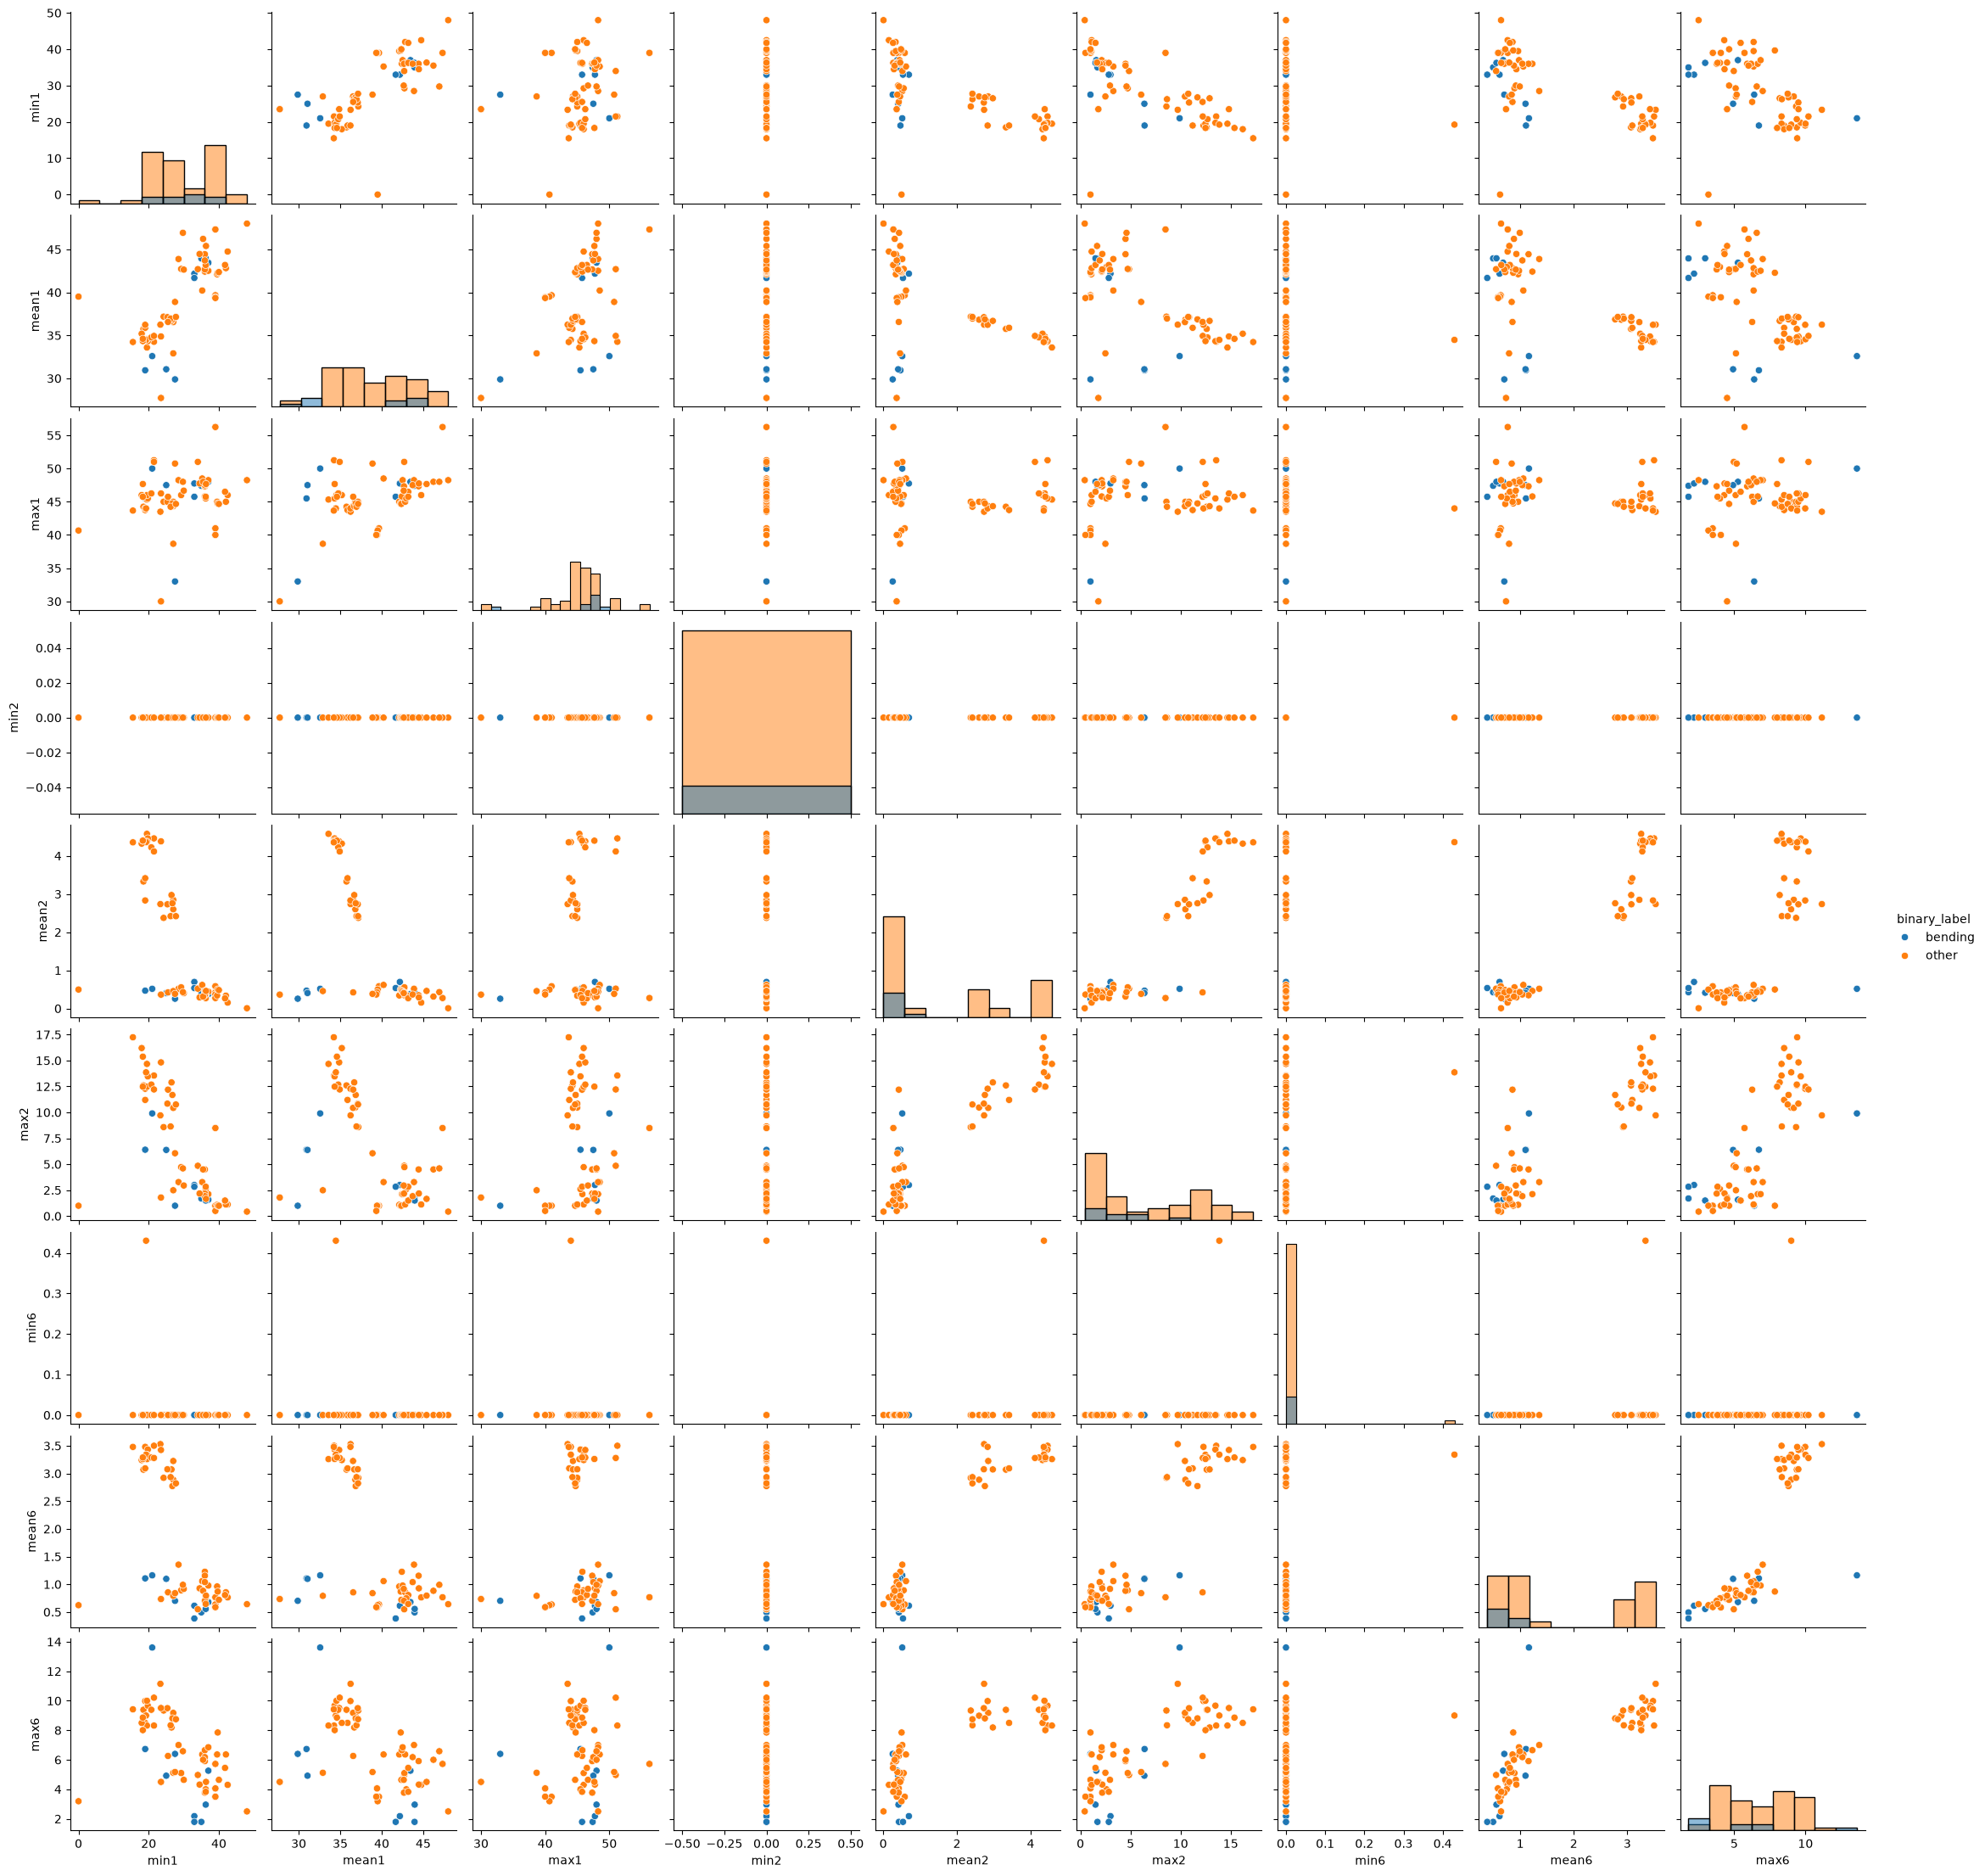

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

feature_df["binary_label"] = feature_df["activity"].apply(
    lambda x: "bending" if x in ["bending1", "bending2"] else "other"
)

selected_features = [
    "min1", "mean1", "max1",
    "min2", "mean2", "max2",
    "min6", "mean6", "max6"
]

plot_data = feature_df[selected_features + ["binary_label"]]

sns.pairplot(
    plot_data,
    hue="binary_label",
    diag_kind="hist"
)

plt.show()

The scatter plots show the minimum, mean, and maximum features extracted
from time series 1, 2, and 6.

The bending activities are relatively well separated from the other activities
for several feature combinations, especially those involving the mean features.
However, there is still some overlap between the two classes, so the separation
is not perfect.

#### 2(a)ii Splitting Each Time Series into Two Parts

In [9]:
def extract_split_features(data, num_parts=2):
    features = {}

    for i, column in enumerate(time_series_columns, start=1):
        parts = np.array_split(data[column], num_parts)

        for j, part in enumerate(parts, start=1):
            features[f"min{i}_part{j}"] = part.min()
            features[f"mean{i}_part{j}"] = part.mean()
            features[f"max{i}_part{j}"] = part.max()

    return features


split_features = []

for folder, file in train_data:
    file_path = os.path.join(folder, file)

    with open(file_path, "r") as f:
        lines = f.readlines()

    cleaned_lines = [
        line.rstrip().rstrip(",")
        for line in lines[5:]
    ]

    data = pd.read_csv(
        StringIO("\n".join(cleaned_lines)),
        header=None,
        names=column_names,
        sep=r",|\s+",
        engine="python"
    )

    data[time_series_columns] = data[time_series_columns].apply(
        pd.to_numeric,
        errors="coerce"
    )

    data[time_series_columns] = (
        data[time_series_columns]
        .interpolate()
        .bfill()
        .ffill()
    )

    features = extract_split_features(data, num_parts=2)

    features["activity"] = folder
    features["binary_label"] = (
        "bending"
        if folder in ["bending1", "bending2"]
        else "other"
    )

    split_features.append(features)

split_feature_df = pd.DataFrame(split_features)

print("Number of training instances:", split_feature_df.shape[0])
print("Number of columns:", split_feature_df.shape[1])

split_feature_df.head()

Number of training instances: 69
Number of columns: 38


,min1_part1,mean1_part1,max1_part1,min1_part2,mean1_part2,max1_part2,min2_part1,mean2_part1,max2_part1,min2_part2,...,mean5_part2,max5_part2,min6_part1,mean6_part1,max6_part1,min6_part2,mean6_part2,max6_part2,activity,binary_label
0,36.50,44.057167,46.50,35.00,43.851833,47.40,0.0,0.381042,1.50,0.0,...,34.883375,38.25,0.0,0.598250,1.79,0.0,0.388333,1.50,bending1,bending
1,33.75,43.278875,47.75,33.00,41.080750,46.00,0.0,0.673292,3.00,0.0,...,30.965708,38.50,0.0,0.640958,1.53,0.0,0.586083,2.18,bending1,bending
2,33.00,41.621208,45.75,39.25,41.734917,43.67,0.0,0.623083,2.83,0.0,...,29.635833,36.00,0.0,0.419083,1.79,0.0,0.347500,1.50,bending1,bending
3,39.00,44.117042,48.00,37.00,42.792875,46.50,0.0,0.250042,1.30,0.0,...,22.850875,26.00,0.0,0.815417,5.26,0.0,0.543875,4.06,bending1,bending
4,36.67,43.486208,45.00,36.25,44.452042,48.00,0.0,0.378667,1.30,0.0,...,21.882042,26.00,0.0,0.524875,2.28,0.0,0.585750,2.96,bending1,bending


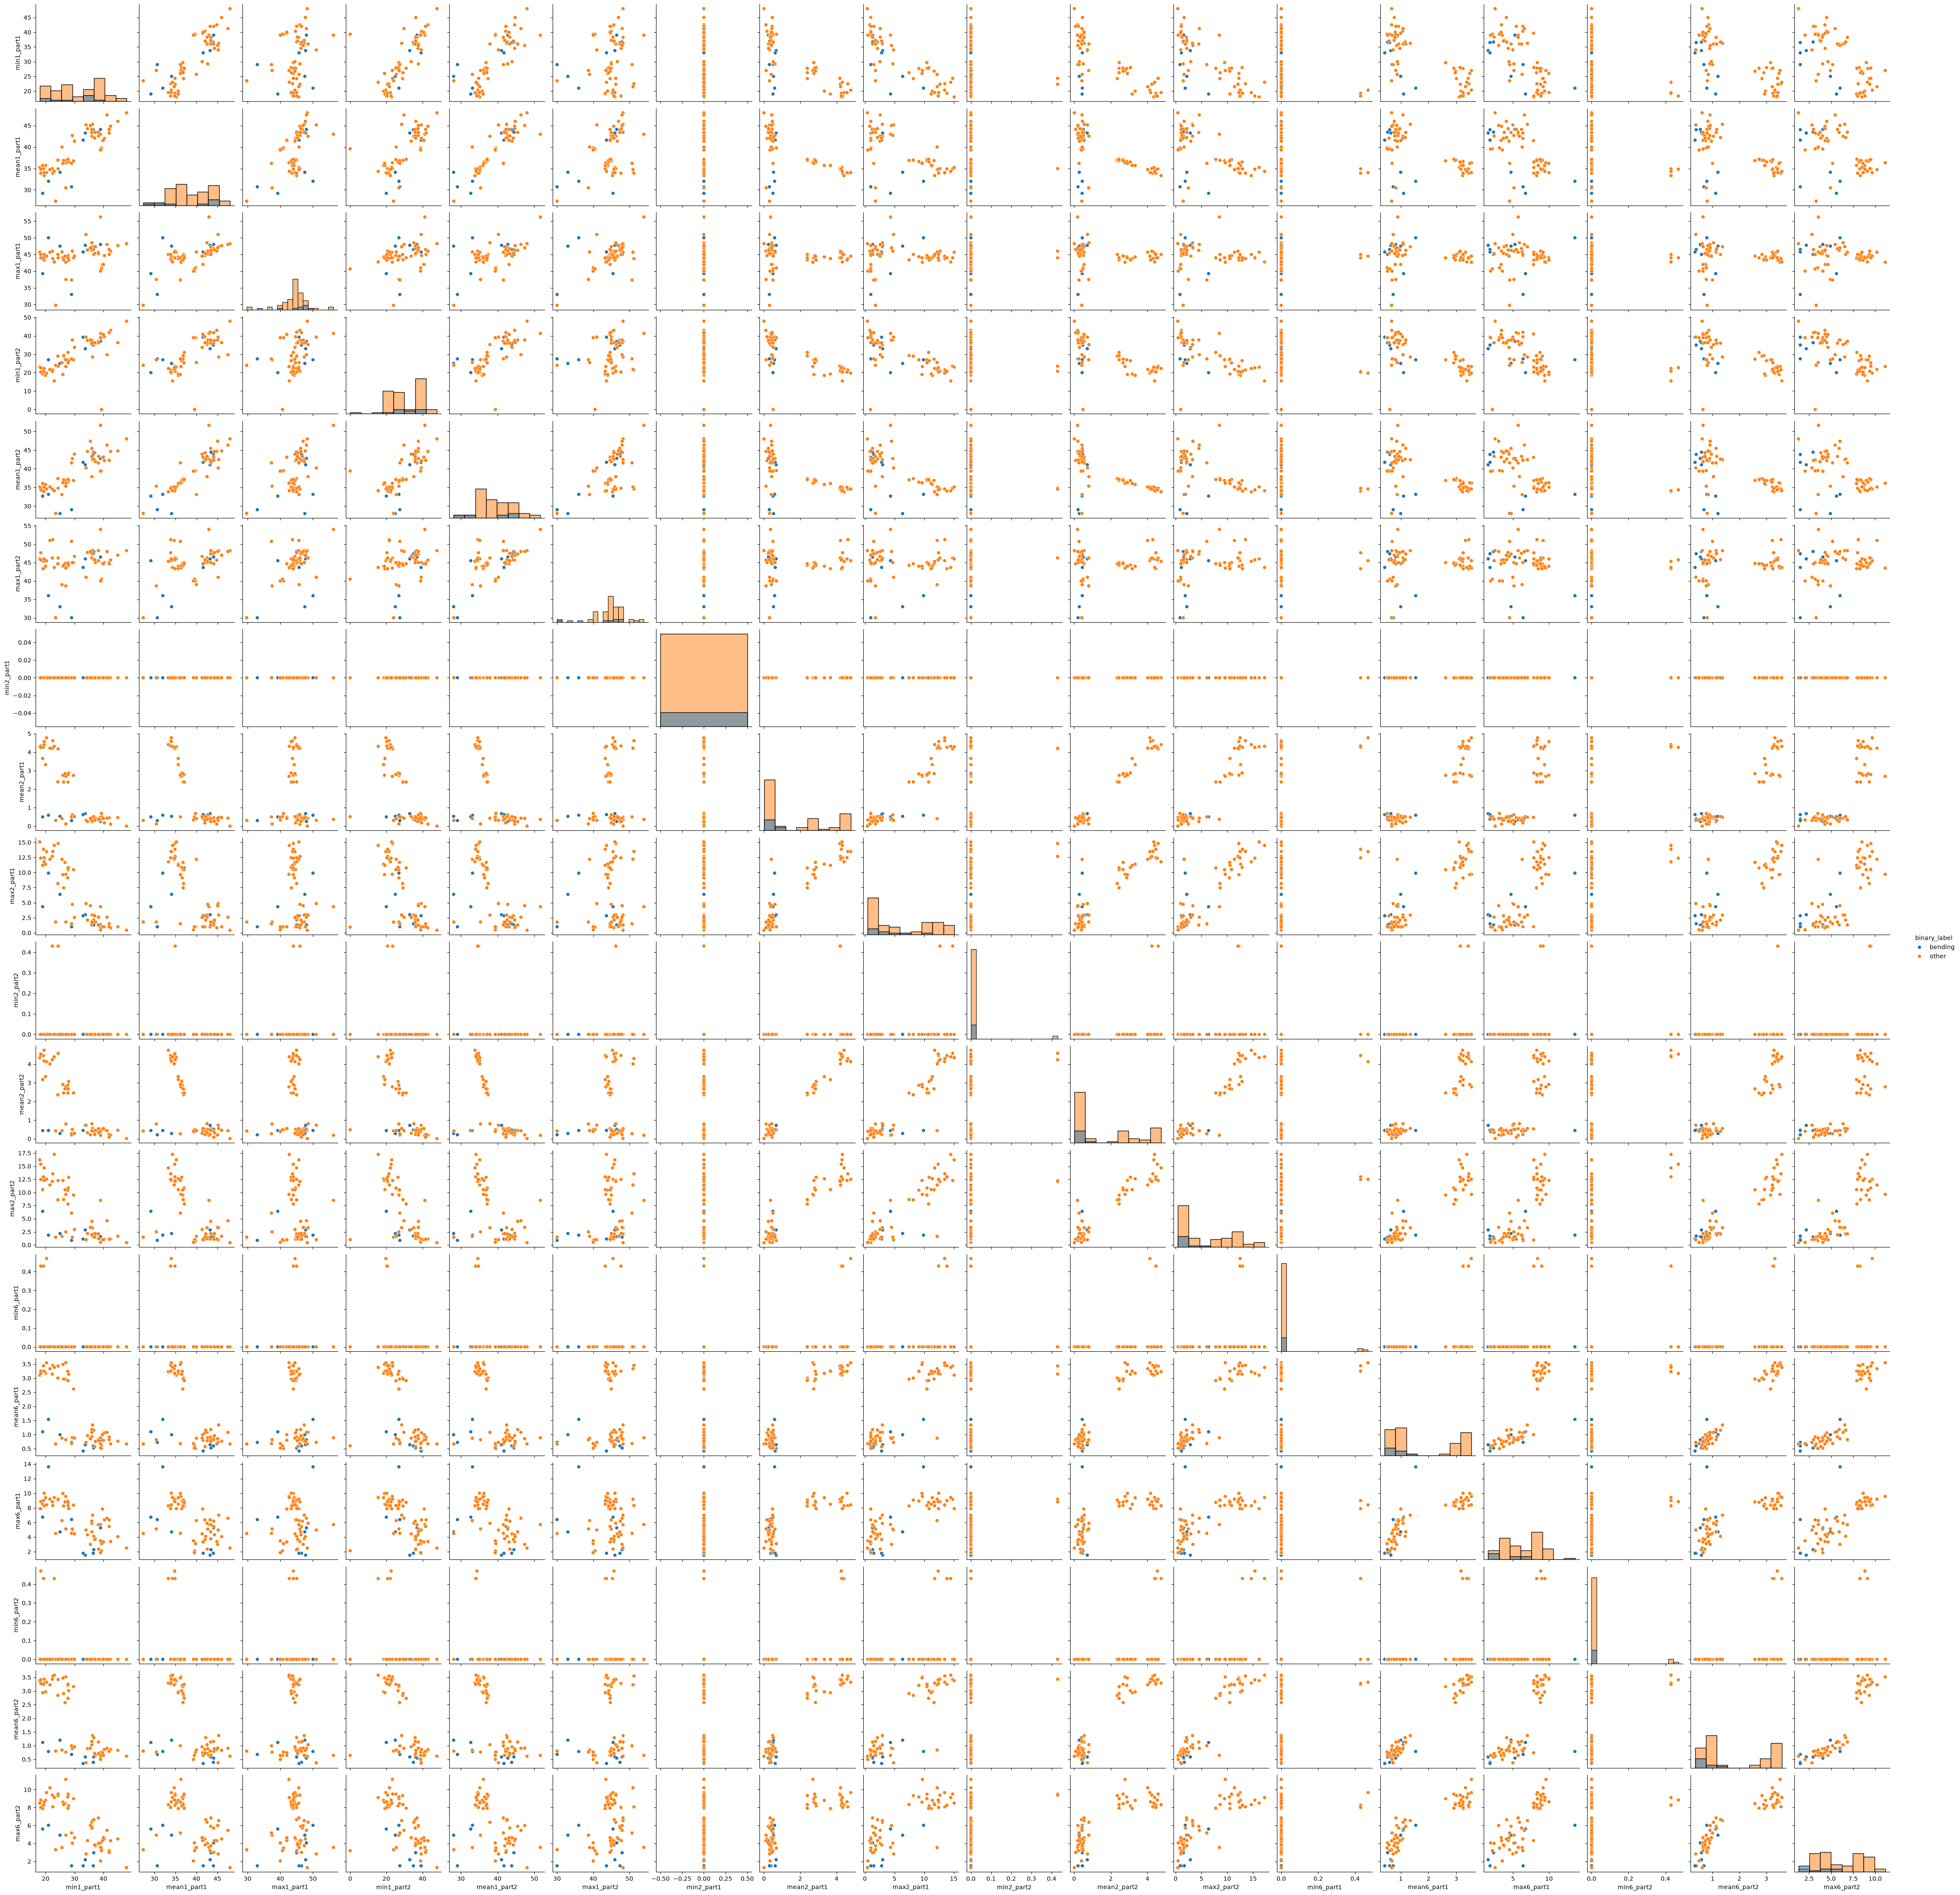

In [10]:
selected_split_features = [
    "min1_part1", "mean1_part1", "max1_part1",
    "min1_part2", "mean1_part2", "max1_part2",

    "min2_part1", "mean2_part1", "max2_part1",
    "min2_part2", "mean2_part2", "max2_part2",

    "min6_part1", "mean6_part1", "max6_part1",
    "min6_part2", "mean6_part2", "max6_part2"
]

plot_data_split = split_feature_df[
    selected_split_features + ["binary_label"]
]

sns.pairplot(
    plot_data_split,
    hue="binary_label",
    diag_kind="hist"
)

plt.show()

Compared with 2(a)i, splitting each time series into two parts provides more
detailed information about the temporal behavior of the activities. Some feature
combinations show slightly better separation between bending and other activities,
although considerable overlap still remains. Therefore, the improvement in class
separation is noticeable in some plots but is not dramatic overall.

#### 2(a)iii Logistic Regression with Cross-Validation and Feature Selection

In [11]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

def extract_features_for_l(data, l):
    features = {}

    for i, column in enumerate(time_series_columns, start=1):
        parts = np.array_split(data[column].to_numpy(), l)

        for j, part in enumerate(parts, start=1):
            features[f"min{i}_part{j}"] = np.min(part)
            features[f"max{i}_part{j}"] = np.max(part)
            features[f"mean{i}_part{j}"] = np.mean(part)
            features[f"median{i}_part{j}"] = np.median(part)
            features[f"std{i}_part{j}"] = np.std(part, ddof=0)
            features[f"1st_quart{i}_part{j}"] = np.percentile(part, 25)
            features[f"3rd_quart{i}_part{j}"] = np.percentile(part, 75)

    return features

In [12]:
def build_dataset_for_l(file_list, l):
    rows = []

    for folder, file in file_list:
        file_path = os.path.join(folder, file)

        with open(file_path, "r") as f:
            lines = f.readlines()

        cleaned_lines = [
            line.rstrip().rstrip(",")
            for line in lines[5:]
        ]

        data = pd.read_csv(
            StringIO("\n".join(cleaned_lines)),
            header=None,
            names=column_names,
            sep=r",|\s+",
            engine="python"
        )

        # Clean the six time-series columns
        data[time_series_columns] = data[time_series_columns].apply(
            pd.to_numeric,
            errors="coerce"
        )

        data[time_series_columns] = (
            data[time_series_columns]
            .interpolate()
            .bfill()
            .ffill()
        )

        features = extract_features_for_l(data, l)

        features["label"] = (
            1 if folder in ["bending1", "bending2"] else 0
        )

        rows.append(features)

    return pd.DataFrame(rows)

In [13]:
test_l1 = build_dataset_for_l(train_data, 1)

print("Shape:", test_l1.shape)
print("Class distribution:")
print(test_l1["label"].value_counts())

test_l1.head()

Shape: (69, 43)
Class distribution:
label
0    60
1     9
Name: count, dtype: int64


,min1_part1,max1_part1,mean1_part1,median1_part1,std1_part1,1st_quart1_part1,3rd_quart1_part1,min2_part1,max2_part1,mean2_part1,...,1st_quart5_part1,3rd_quart5_part1,min6_part1,max6_part1,mean6_part1,median6_part1,std6_part1,1st_quart6_part1,3rd_quart6_part1,label
0,35.00,47.40,43.954500,44.33,1.557210,43.00,45.00,0.0,1.70,0.426250,...,35.3625,36.50,0.0,1.79,0.493292,0.43,0.512971,0.00,0.94,1
1,33.00,47.75,42.179812,43.50,3.666840,39.15,45.00,0.0,3.00,0.696042,...,30.4575,36.33,0.0,2.18,0.613521,0.50,0.523771,0.00,1.00,1
2,33.00,45.75,41.678063,41.75,2.241152,41.33,42.75,0.0,2.83,0.535979,...,28.4575,31.25,0.0,1.79,0.383292,0.43,0.388759,0.00,0.50,1
3,37.00,48.00,43.454958,43.25,1.384653,42.50,45.00,0.0,1.58,0.378083,...,22.2500,24.00,0.0,5.26,0.679646,0.50,0.621885,0.43,0.87,1
4,36.25,48.00,43.969125,44.50,1.616677,43.31,44.67,0.0,1.50,0.413125,...,20.5000,23.75,0.0,2.96,0.555312,0.49,0.487318,0.00,0.83,1


In [14]:
from sklearn.feature_selection import RFECV

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

for l in range(1, 21):

    print(f"Processing l = {l}...")

    dataset_l = build_dataset_for_l(train_data, l)

    X = dataset_l.drop(columns=["label"])
    y = dataset_l["label"]

    # Very large C minimizes the effect of L2 regularization
    logistic_model = LogisticRegression(
        C=1e6,
        solver="liblinear",
        max_iter=2000
    )

    rfecv = RFECV(
        estimator=logistic_model,
        step=0.1,
        cv=cv,
        scoring="accuracy",
        min_features_to_select=1
    )

    rfecv.fit(X, y)

    best_p = rfecv.n_features_
    best_score = np.max(rfecv.cv_results_["mean_test_score"])

    results.append({
        "l": l,
        "p": best_p,
        "cv_accuracy": best_score
    })

results_df = pd.DataFrame(results)

results_df

Processing l = 1...
Processing l = 2...
Processing l = 3...
Processing l = 4...
Processing l = 5...
Processing l = 6...
Processing l = 7...
Processing l = 8...
Processing l = 9...
Processing l = 10...
Processing l = 11...
Processing l = 12...
Processing l = 13...
Processing l = 14...
Processing l = 15...
Processing l = 16...
Processing l = 17...
Processing l = 18...
Processing l = 19...
Processing l = 20...


,l,p,cv_accuracy
0,1,10,1.000000
1,2,4,0.957143
2,3,6,0.957143
3,4,8,0.971429
4,5,21,0.971429
5,6,27,0.957143
6,7,33,0.970330
7,8,39,0.942857
8,9,8,0.970330
9,10,42,0.956044


In [15]:
best_result = results_df.loc[
    results_df["cv_accuracy"].idxmax()
]

best_l = int(best_result["l"])
best_p = int(best_result["p"])
best_cv_accuracy = best_result["cv_accuracy"]

print("Best l:", best_l)
print("Best p:", best_p)
print("Best cross-validation accuracy:", best_cv_accuracy)

Best l: 1
Best p: 10
Best cross-validation accuracy: 1.0


In [16]:
results_df[results_df["cv_accuracy"] == results_df["cv_accuracy"].max()]

,l,p,cv_accuracy
0,1,10,1.0


The best combination is l = 1 and p = 10, with a 5-fold stratified
cross-validation accuracy of 1.0.

The correct way to perform cross-validation is to conduct feature selection
within each training fold of the cross-validation procedure. The wrong way is
to select features using the entire training set before cross-validation, because
that would introduce data leakage and lead to an optimistically biased estimate
of model performance.

Stratified 5-fold cross-validation is used because the binary classes are
imbalanced, with substantially fewer bending instances than non-bending instances.

#### 2(a)iv Confusion Matrix, ROC, AUC, Coefficients, and P-values

In [17]:
final_train_df = build_dataset_for_l(train_data, best_l)

X_train_final = final_train_df.drop(columns=["label"])
y_train_final = final_train_df["label"]

base_model = LogisticRegression(
    C=1e6,
    solver="liblinear",
    max_iter=2000
)

rfe_final = RFE(
    estimator=base_model,
    n_features_to_select=best_p
)

rfe_final.fit(X_train_final, y_train_final)

selected_features = X_train_final.columns[rfe_final.support_]

print("Selected features:")
for feature in selected_features:
    print(feature)

Selected features:
mean1_part1
3rd_quart1_part1
max2_part1
3rd_quart2_part1
median3_part1
min5_part1
max5_part1
mean5_part1
1st_quart5_part1
max6_part1


In [18]:
X_train_selected = X_train_final[selected_features]

final_model = LogisticRegression(
    C=1e6,
    solver="liblinear",
    max_iter=2000
)

final_model.fit(X_train_selected, y_train_final)

y_train_pred = final_model.predict(X_train_selected)
y_train_prob = final_model.predict_proba(X_train_selected)[:, 1]

Confusion Matrix:
[[60  0]
 [ 0  9]]


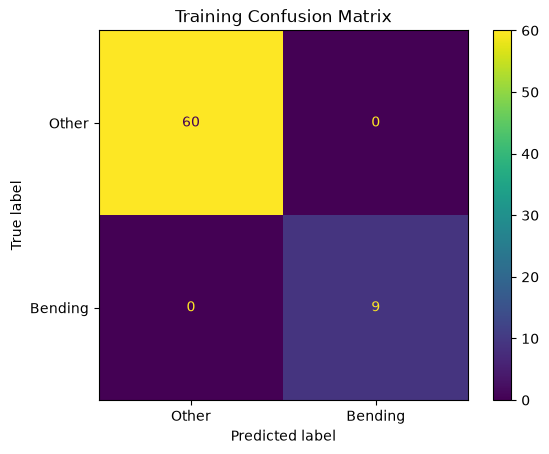

In [19]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)

cm = confusion_matrix(y_train_final, y_train_pred)

print("Confusion Matrix:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Other", "Bending"]
).plot()

plt.title("Training Confusion Matrix")
plt.show()

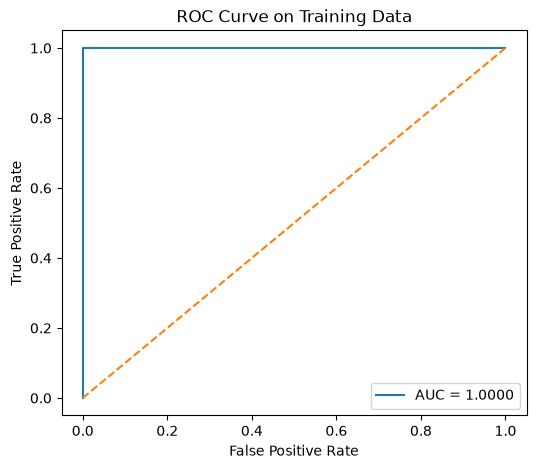

Training AUC: 1.0


In [20]:
fpr, tpr, thresholds = roc_curve(
    y_train_final,
    y_train_prob
)

auc_score = roc_auc_score(
    y_train_final,
    y_train_prob
)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"AUC = {auc_score:.4f}")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve on Training Data")
plt.legend()

plt.show()

print("Training AUC:", auc_score)

In [21]:
import statsmodels.api as sm

X_sm = sm.add_constant(X_train_selected)

logit_model = sm.Logit(
    y_train_final,
    X_sm
)

logit_result = logit_model.fit(
    disp=False,
    maxiter=200
)

coef_table = pd.DataFrame({
    "Coefficient": logit_result.params,
    "P-value": logit_result.pvalues
})

coef_table

D:\python\Python\Lib\site-packages\statsmodels\base\optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
D:\python\Python\Lib\site-packages\statsmodels\base\optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
D:\python\Python\Lib\site-packages\statsmodels\base\optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
D:\python\Python\Lib\site-packages\statsmodels\base\optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
D:\python\Python\Lib\site-packages\statsmodels\base\optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
D:\python\Python\Lib\site-packages\

,Coefficient,P-value
const,-69.376004,1.000000
mean1_part1,-3.015200,1.000000
3rd_quart1_part1,0.204959,1.000000
max2_part1,-1.928128,1.000000
3rd_quart2_part1,-2.900411,1.000000
median3_part1,-2.940750,1.000000
min5_part1,6.394108,1.000000
max5_part1,6.424841,0.999999
mean5_part1,-0.253170,1.000000
1st_quart5_part1,0.350119,1.000000


The fitted logistic regression model shows perfect or near-perfect separation
between the two classes. As a result, the maximum likelihood estimates of the
logistic regression parameters are unstable, and the associated p-values are
not reliable. This is also reflected by the PerfectSeparationWarning produced
by statsmodels. Therefore, the reported coefficients and p-values should be interpreted with caution.

#### 2(a)v Test Set Evaluation

In [22]:
final_test_df = build_dataset_for_l(test_data, best_l)

X_test_final = final_test_df.drop(columns=["label"])
y_test_final = final_test_df["label"]

X_test_selected = X_test_final[selected_features]

y_test_pred = final_model.predict(X_test_selected)
y_test_prob = final_model.predict_proba(X_test_selected)[:, 1]

In [23]:
from sklearn.metrics import accuracy_score

test_accuracy = accuracy_score(
    y_test_final,
    y_test_pred
)

print("Cross-validation accuracy:", best_cv_accuracy)
print("Test accuracy:", test_accuracy)

Cross-validation accuracy: 1.0
Test accuracy: 1.0


Test Confusion Matrix:
[[15  0]
 [ 0  4]]


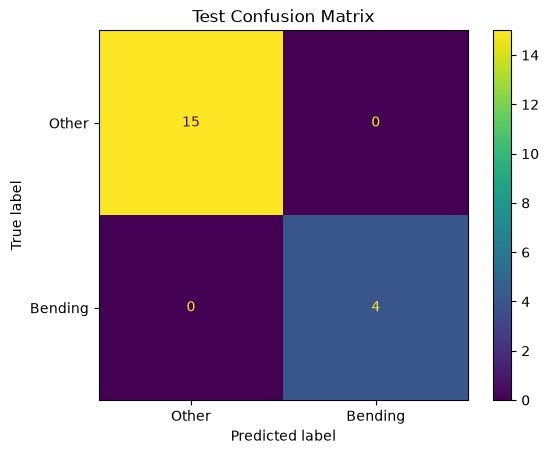

In [24]:
test_cm = confusion_matrix(
    y_test_final,
    y_test_pred
)

print("Test Confusion Matrix:")
print(test_cm)

ConfusionMatrixDisplay(
    confusion_matrix=test_cm,
    display_labels=["Other", "Bending"]
).plot()

plt.title("Test Confusion Matrix")
plt.show()

The test accuracy is 1.0, which is the same as the 5-fold cross-validation
accuracy of 1.0.

The test confusion matrix shows that all 19 test instances were classified
correctly: all 15 non-bending instances and all 4 bending instances were
correctly predicted.

Therefore, the test performance is consistent with the cross-validation
performance, although the perfect classification also suggests that the two
classes may be very well separated.

#### 2(a)vi Separation and Logistic Regression Stability

Yes. The two classes appear to be very well separated. The classifier achieved
perfect cross-validation and test accuracy, and statsmodels produced a
PerfectSeparationWarning during logistic regression fitting.

This indicates that the logistic regression parameters are unstable under
maximum likelihood estimation because some linear combination of the selected
features can perfectly or nearly perfectly separate the two classes.

#### 2(a)vii Class Imbalance and Case-Control Sampling

In [25]:
case_control_df = X_train_selected.copy()
case_control_df["label"] = y_train_final.values

bending_samples = case_control_df[case_control_df["label"] == 1]
other_samples = case_control_df[case_control_df["label"] == 0]

other_sampled = other_samples.sample(
    n=len(bending_samples),
    random_state=42
)

balanced_df = pd.concat(
    [bending_samples, other_sampled],
    ignore_index=True
)

balanced_df = balanced_df.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

X_balanced = balanced_df.drop(columns=["label"])
y_balanced = balanced_df["label"]

print("Original class distribution:")
print(y_train_final.value_counts())

print("\nCase-control class distribution:")
print(y_balanced.value_counts())

Original class distribution:
label
0    60
1     9
Name: count, dtype: int64

Case-control class distribution:
label
1    9
0    9
Name: count, dtype: int64


In [26]:
case_control_model = LogisticRegression(
    C=1e6,
    solver="liblinear",
    max_iter=2000
)

case_control_model.fit(X_balanced, y_balanced)

pi_original = y_train_final.mean()
pi_sample = y_balanced.mean()

intercept_adjustment = (
    np.log(pi_original / (1 - pi_original))
    - np.log(pi_sample / (1 - pi_sample))
)

adjusted_intercept = (
    case_control_model.intercept_[0]
    + intercept_adjustment
)

print("Original fitted intercept:", case_control_model.intercept_[0])
print("Adjusted intercept:", adjusted_intercept)

Original fitted intercept: -0.049401871322778936
Adjusted intercept: -1.9465218562086601


In [27]:
linear_score = (
    adjusted_intercept
    + X_train_selected.to_numpy() @ case_control_model.coef_[0]
)

adjusted_prob = 1 / (1 + np.exp(-linear_score))
adjusted_pred = (adjusted_prob >= 0.5).astype(int)

Case-Control Confusion Matrix:
[[60  0]
 [ 0  9]]


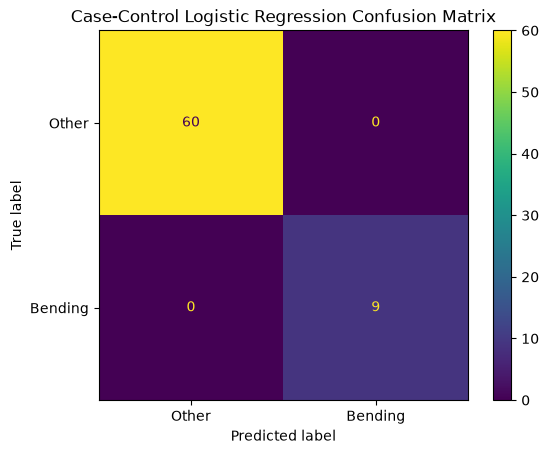

In [28]:
cc_cm = confusion_matrix(
    y_train_final,
    adjusted_pred
)

print("Case-Control Confusion Matrix:")
print(cc_cm)

ConfusionMatrixDisplay(
    confusion_matrix=cc_cm,
    display_labels=["Other", "Bending"]
).plot()

plt.title("Case-Control Logistic Regression Confusion Matrix")
plt.show()

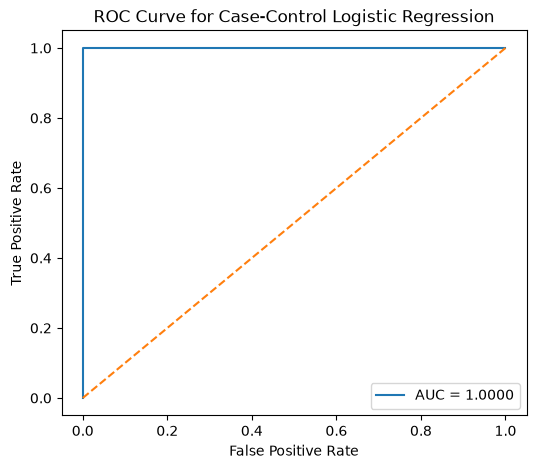

Case-Control AUC: 1.0


In [29]:
cc_auc = roc_auc_score(
    y_train_final,
    adjusted_prob
)

cc_fpr, cc_tpr, _ = roc_curve(
    y_train_final,
    adjusted_prob
)

plt.figure(figsize=(6, 5))

plt.plot(
    cc_fpr,
    cc_tpr,
    label=f"AUC = {cc_auc:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve for Case-Control Logistic Regression")
plt.legend()

plt.show()

print("Case-Control AUC:", cc_auc)

The original training data are imbalanced, with 60 non-bending instances and
only 9 bending instances. Therefore, case-control sampling was used to create
a balanced sample containing equal numbers of bending and non-bending instances.

Because case-control sampling changes the class proportions, the intercept of
the logistic regression model was adjusted to reflect the original class
distribution.

The adjusted case-control logistic regression achieved perfect classification on
the original training set, with a confusion matrix of [[60, 0], [0, 9]] and an
AUC of 1.0.

This indicates that class imbalance does not appear to be the main reason for the
high classification performance. The two classes remain extremely well separated
even after balancing the training sample.

### 2(b) Binary Classification Using L1-Penalized Logistic Regression

#### 2(b)i L1-Penalized Logistic Regression

In [30]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

C_values = np.logspace(-4, 4, 10)

l1_results = []

for l in range(1, 21):
    print(f"Processing l = {l}...")

    dataset_l = build_dataset_for_l(train_data, l)

    X = dataset_l.drop(columns=["label"])
    y = dataset_l["label"]

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("logistic", LogisticRegression(
            solver="liblinear",
            l1_ratio=1,
            max_iter=3000,
        ))
    ])

    param_grid = {
        "logistic__C": C_values
    }

    grid = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )

    grid.fit(X, y)

    l1_results.append({
        "l": l,
        "C": grid.best_params_["logistic__C"],
        "cv_accuracy": grid.best_score_
    })

l1_results_df = pd.DataFrame(l1_results)

l1_results_df

Processing l = 1...
Processing l = 2...
Processing l = 3...
Processing l = 4...
Processing l = 5...
Processing l = 6...
Processing l = 7...
Processing l = 8...
Processing l = 9...
Processing l = 10...
Processing l = 11...
Processing l = 12...
Processing l = 13...
Processing l = 14...
Processing l = 15...
Processing l = 16...
Processing l = 17...
Processing l = 18...
Processing l = 19...
Processing l = 20...


,l,C,cv_accuracy
0,1,10000.000000,0.985714
1,2,1291.549665,0.971429
2,3,0.359381,0.957143
3,4,0.359381,0.957143
4,5,21.544347,0.941758
5,6,21.544347,0.957143
6,7,166.810054,0.956044
7,8,166.810054,0.942857
8,9,2.782559,0.941758
9,10,166.810054,0.971429


In [31]:
best_l1_result = l1_results_df.loc[
    l1_results_df["cv_accuracy"].idxmax()
]

best_l_l1 = int(best_l1_result["l"])
best_C_l1 = best_l1_result["C"]
best_l1_cv_accuracy = best_l1_result["cv_accuracy"]

print("Best l:", best_l_l1)
print("Best C:", best_C_l1)
print("Best L1 cross-validation accuracy:", best_l1_cv_accuracy)

Best l: 1
Best C: 10000.0
Best L1 cross-validation accuracy: 0.9857142857142858


#### 2(b)ii Comparison

The logistic regression model with feature selection in 2(a) achieved a
cross-validation accuracy of 1.0, while the L1-penalized logistic regression
achieved a cross-validation accuracy of approximately 0.9857.

Therefore, the feature-selection approach performed slightly better in terms of
cross-validation accuracy for this dataset.

However, L1-penalized logistic regression is easier to implement because feature
selection is performed automatically through regularization. In contrast, the
previous approach requires an additional feature-selection procedure such as RFE
or p-value-based variable selection.

Overall, the feature-selection approach achieved slightly better predictive
performance, while L1 regularization provides a simpler and more convenient
implementation.

### 2(c) Multi-class Classification

#### 2(c)i L1-Penalized Multinomial Logistic Regression

In [32]:
def build_multiclass_dataset_for_l(file_list, l):
    rows = []

    for folder, file in file_list:
        file_path = os.path.join(folder, file)

        with open(file_path, "r") as f:
            lines = f.readlines()

        cleaned_lines = [
            line.rstrip().rstrip(",")
            for line in lines[5:]
        ]

        data = pd.read_csv(
            StringIO("\n".join(cleaned_lines)),
            header=None,
            names=column_names,
            sep=r",|\s+",
            engine="python"
        )

        data[time_series_columns] = data[time_series_columns].apply(
            pd.to_numeric,
            errors="coerce"
        )

        data[time_series_columns] = (
            data[time_series_columns]
            .interpolate()
            .bfill()
            .ffill()
        )

        features = extract_features_for_l(data, l)

        features["label"] = folder

        rows.append(features)

    return pd.DataFrame(rows)

In [33]:
C_values_multi = [0.01, 0.1, 1, 10, 100]

multi_cv = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

multiclass_results = []

for l in range(1, 21):
    print(f"Processing l = {l}...")

    dataset_l = build_multiclass_dataset_for_l(train_data, l)

    X = dataset_l.drop(columns=["label"])
    y = dataset_l["label"]

    best_score_for_l = -1
    best_C_for_l = None

    for C in C_values_multi:
        model = Pipeline([
            ("scaler", StandardScaler()),
            ("logistic", LogisticRegression(
                solver="saga",
                l1_ratio=1,
                C=C,
                max_iter=10000
            ))
        ])

        scores = cross_val_score(
            model,
            X,
            y,
            cv=multi_cv,
            scoring="accuracy"
        )

        mean_score = scores.mean()

        if mean_score > best_score_for_l:
            best_score_for_l = mean_score
            best_C_for_l = C

    multiclass_results.append({
        "l": l,
        "C": best_C_for_l,
        "cv_accuracy": best_score_for_l
    })

multiclass_results_df = pd.DataFrame(multiclass_results)

multiclass_results_df

Processing l = 1...
Processing l = 2...
Processing l = 3...
Processing l = 4...
Processing l = 5...
Processing l = 6...
Processing l = 7...
Processing l = 8...
Processing l = 9...
Processing l = 10...
Processing l = 11...
Processing l = 12...
Processing l = 13...
Processing l = 14...
Processing l = 15...
Processing l = 16...
Processing l = 17...
Processing l = 18...
Processing l = 19...
Processing l = 20...


,l,C,cv_accuracy
0,1,10,0.913399
1,2,10,0.898693
2,3,100,0.841503
3,4,100,0.855392
4,5,100,0.868464
5,6,100,0.883987
6,7,10,0.853758
7,8,100,0.853758
8,9,10,0.839052
9,10,100,0.824346


In [34]:
best_multi_result = multiclass_results_df.loc[
    multiclass_results_df["cv_accuracy"].idxmax()
]

best_l_multi = int(best_multi_result["l"])
best_C_multi = best_multi_result["C"]
best_multi_cv_accuracy = best_multi_result["cv_accuracy"]

print("Best l:", best_l_multi)
print("Best C:", best_C_multi)
print("Best multiclass CV accuracy:", best_multi_cv_accuracy)

Best l: 1
Best C: 10.0
Best multiclass CV accuracy: 0.9133986928104575


In [35]:
multi_train_df = build_multiclass_dataset_for_l(
    train_data,
    best_l_multi
)

multi_test_df = build_multiclass_dataset_for_l(
    test_data,
    best_l_multi
)

X_multi_train = multi_train_df.drop(columns=["label"])
y_multi_train = multi_train_df["label"]

X_multi_test = multi_test_df.drop(columns=["label"])
y_multi_test = multi_test_df["label"]

final_multi_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(
        solver="saga",
        l1_ratio=1,
        C=best_C_multi,
        max_iter=10000
    ))
])

final_multi_model.fit(
    X_multi_train,
    y_multi_train
)

y_multi_pred = final_multi_model.predict(
    X_multi_test
)

y_multi_prob = final_multi_model.predict_proba(
    X_multi_test
)

In [36]:
multi_test_accuracy = accuracy_score(
    y_multi_test,
    y_multi_pred
)

multi_test_error = 1 - multi_test_accuracy

print("Multiclass test accuracy:", multi_test_accuracy)
print("Multiclass test error:", multi_test_error)

Multiclass test accuracy: 0.9473684210526315
Multiclass test error: 0.052631578947368474


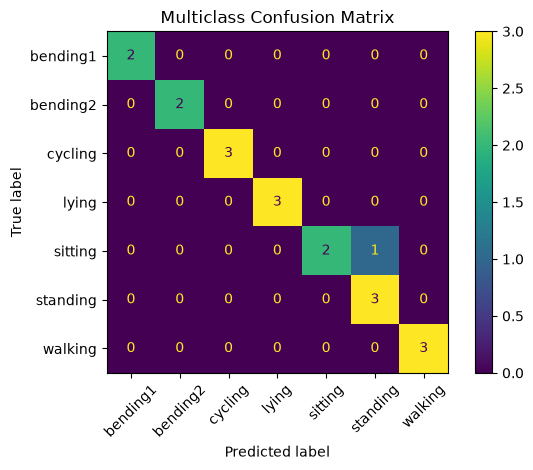

In [37]:
multi_cm = confusion_matrix(
    y_multi_test,
    y_multi_pred,
    labels=final_multi_model.classes_
)

ConfusionMatrixDisplay(
    confusion_matrix=multi_cm,
    display_labels=final_multi_model.classes_
).plot(
    xticks_rotation=45
)

plt.title("Multiclass Confusion Matrix")
plt.tight_layout()
plt.show()

The multiclass L1-penalized logistic regression correctly classified 18 out of
19 test instances, resulting in a test accuracy of approximately 0.9474 and a
test error of approximately 0.0526.

All activity classes were classified correctly except for one sitting instance,
which was misclassified as standing. Overall, the classifier achieved strong
multiclass performance on the test set.

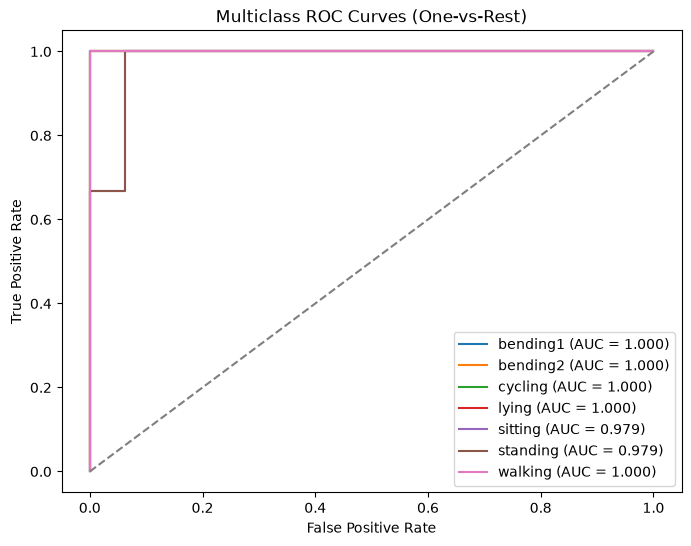

In [38]:
from sklearn.preprocessing import label_binarize

classes = final_multi_model.classes_

y_test_bin = label_binarize(
    y_multi_test,
    classes=classes
)

plt.figure(figsize=(8, 6))

for i, class_name in enumerate(classes):
    fpr_i, tpr_i, _ = roc_curve(
        y_test_bin[:, i],
        y_multi_prob[:, i]
    )

    auc_i = roc_auc_score(
        y_test_bin[:, i],
        y_multi_prob[:, i]
    )

    plt.plot(
        fpr_i,
        tpr_i,
        label=f"{class_name} (AUC = {auc_i:.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass ROC Curves (One-vs-Rest)")
plt.legend()
plt.show()

For the multiclass problem, ROC curves were constructed using the one-vs-rest
approach. Each activity class was treated as the positive class in turn, while
all remaining classes were treated as the negative class.

The ROC results show excellent class discrimination. Most classes achieve an AUC
of 1.0, while sitting and standing each achieve an AUC of approximately 0.979,
which is consistent with the confusion matrix where one sitting instance was
misclassified as standing.

#### 2(c)ii Naive Bayes Classification

In [39]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score

gaussian_nb = GaussianNB()

gaussian_nb.fit(
    X_multi_train,
    y_multi_train
)

gaussian_pred = gaussian_nb.predict(
    X_multi_test
)

gaussian_accuracy = accuracy_score(
    y_multi_test,
    gaussian_pred
)

gaussian_error = 1 - gaussian_accuracy

print("Gaussian Naive Bayes accuracy:", gaussian_accuracy)
print("Gaussian Naive Bayes test error:", gaussian_error)

Gaussian Naive Bayes accuracy: 0.8947368421052632
Gaussian Naive Bayes test error: 0.10526315789473684


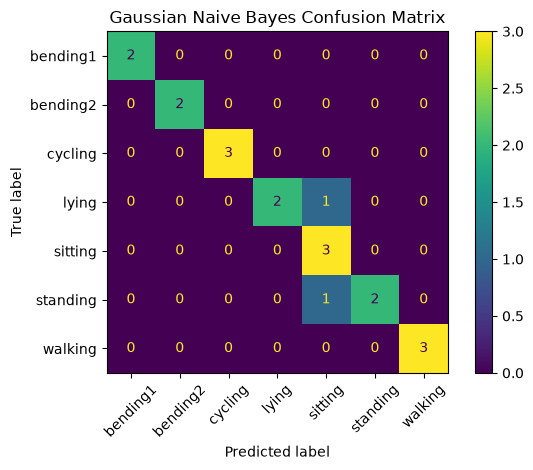

In [40]:
gaussian_cm = confusion_matrix(
    y_multi_test,
    gaussian_pred,
    labels=gaussian_nb.classes_
)

ConfusionMatrixDisplay(
    confusion_matrix=gaussian_cm,
    display_labels=gaussian_nb.classes_
).plot(
    xticks_rotation=45
)

plt.title("Gaussian Naive Bayes Confusion Matrix")
plt.tight_layout()
plt.show()

In [41]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.preprocessing import MinMaxScaler

minmax_scaler = MinMaxScaler()

X_multi_train_nonnegative = minmax_scaler.fit_transform(
    X_multi_train
)

X_multi_test_nonnegative = minmax_scaler.transform(
    X_multi_test
)

multinomial_nb = MultinomialNB()

multinomial_nb.fit(
    X_multi_train_nonnegative,
    y_multi_train
)

multinomial_pred = multinomial_nb.predict(
    X_multi_test_nonnegative
)

multinomial_accuracy = accuracy_score(
    y_multi_test,
    multinomial_pred
)

multinomial_error = 1 - multinomial_accuracy

print("Multinomial Naive Bayes accuracy:", multinomial_accuracy)
print("Multinomial Naive Bayes test error:", multinomial_error)

Multinomial Naive Bayes accuracy: 0.7894736842105263
Multinomial Naive Bayes test error: 0.21052631578947367


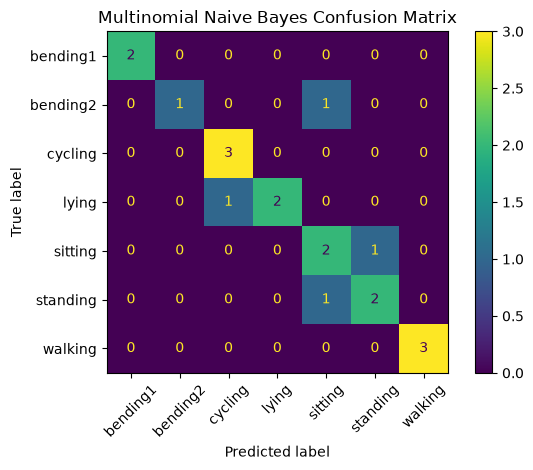

In [42]:
multinomial_cm = confusion_matrix(
    y_multi_test,
    multinomial_pred,
    labels=multinomial_nb.classes_
)

ConfusionMatrixDisplay(
    confusion_matrix=multinomial_cm,
    display_labels=multinomial_nb.classes_
).plot(
    xticks_rotation=45
)

plt.title("Multinomial Naive Bayes Confusion Matrix")
plt.tight_layout()
plt.show()

In [43]:
nb_comparison = pd.DataFrame({
    "Model": [
        "Gaussian Naive Bayes",
        "Multinomial Naive Bayes"
    ],
    "Accuracy": [
        gaussian_accuracy,
        multinomial_accuracy
    ],
    "Test Error": [
        gaussian_error,
        multinomial_error
    ]
})

nb_comparison

,Model,Accuracy,Test Error
0,Gaussian Naive Bayes,0.894737,0.105263
1,Multinomial Naive Bayes,0.789474,0.210526


Gaussian Naive Bayes achieved a test accuracy of approximately 0.8947
and a test error of approximately 0.1053.

Multinomial Naive Bayes achieved a lower test accuracy of approximately
0.7895 and a higher test error of approximately 0.2105.

Therefore, Gaussian Naive Bayes performs better than Multinomial Naive Bayes
for this dataset.

#### 2(c)iii Comparison of Multiclass Classification Methods

Among the three multiclass classification methods, the L1-penalized
multinomial logistic regression performs the best.

Its test accuracy is approximately 0.9474, which is higher than the
Gaussian Naive Bayes accuracy of approximately 0.8947 and the
Multinomial Naive Bayes accuracy of approximately 0.7895.

Therefore, L1-penalized multinomial logistic regression is the best
multiclass classifier for this dataset.

## 3. ISLR 4.8.3

For class \(k\), assume

$$
X \mid Y=k \sim N(\mu_k,\sigma_k^2).
$$

Using Bayes' theorem, the Bayes classifier assigns an observation \(x\) to the class that maximizes

$$
\pi_k f_k(x),
$$

where \(\pi_k\) is the prior probability of class \(k\), and

$$
f_k(x)
=
\frac{1}{\sqrt{2\pi}\sigma_k}
\exp\left(
-\frac{(x-\mu_k)^2}{2\sigma_k^2}
\right).
$$

Taking the logarithm and ignoring the constant term that does not depend on \(k\), the discriminant function is

$$
\delta_k(x)
=
\log(\pi_k)
-
\log(\sigma_k)
-
\frac{(x-\mu_k)^2}{2\sigma_k^2}.
$$

Expanding the squared term gives

$$
\delta_k(x)
=
-\frac{x^2}{2\sigma_k^2}
+
\frac{\mu_k}{\sigma_k^2}x
-
\frac{\mu_k^2}{2\sigma_k^2}
-
\log(\sigma_k)
+
\log(\pi_k).
$$

Since the coefficient of \(x^2\),

$$
-\frac{1}{2\sigma_k^2},
$$

depends on the class \(k\), the quadratic terms do not cancel when the class variances are different.

Therefore, the decision boundary obtained by setting

$$
\delta_k(x)=\delta_l(x)
$$

for two classes is generally a quadratic equation in \(x\), rather than a linear equation.

Hence, the Bayes classifier under QDA is quadratic rather than linear. If all class variances were equal, the \(x^2\) terms would cancel and the classifier would reduce to the linear LDA case.

## 4. ISLR 4.8.7

Using Bayes' theorem,

$$
P(Y=\text{Yes}\mid X=4)
=
\frac{
P(X=4\mid Y=\text{Yes})P(Y=\text{Yes})
}{
P(X=4\mid Y=\text{Yes})P(Y=\text{Yes})
+
P(X=4\mid Y=\text{No})P(Y=\text{No})
}.
$$

The two classes have means

$$
\mu_{\text{Yes}}=10,
\qquad
\mu_{\text{No}}=0,
$$

and common variance

$$
\sigma^2=36.
$$

The normal density is

$$
f(x)
=
\frac{1}{\sqrt{2\pi\sigma^2}}
\exp\left(
-\frac{(x-\mu)^2}{2\sigma^2}
\right).
$$

For \(X=4\),

$$
f_{\text{Yes}}(4)
=
\frac{1}{\sqrt{72\pi}}
\exp\left(
-\frac{(4-10)^2}{72}
\right)
=
\frac{1}{\sqrt{72\pi}}e^{-1/2},
$$

and

$$
f_{\text{No}}(4)
=
\frac{1}{\sqrt{72\pi}}
\exp\left(
-\frac{(4-0)^2}{72}
\right)
=
\frac{1}{\sqrt{72\pi}}e^{-2/9}.
$$

Therefore,

$$
P(Y=\text{Yes}\mid X=4)
=
\frac{
0.8e^{-1/2}
}{
0.8e^{-1/2}+0.2e^{-2/9}
}
\approx 0.752.
$$

Thus, the probability that the company will issue a dividend this year is approximately

$$
\boxed{75.2\%}.
$$